# Data Analytics Project

Project 1

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

LOADING DATASET

In [2]:
df = pd.read_csv('Dataset.csv')

In [3]:
df.head()

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice
0,ORD200000,2023-01-04,C72649,Monitor,5,570.62,928 Main St,Debit Card,Shipped,TRK37947903,7,SAVE10,Instagram,2853.10
1,ORD200001,2024-08-23,C75739,Phone,2,151.35,823 Main St,Online,Shipped,TRK91186779,3,SAVE10,Referral,302.70
2,ORD200002,2024-02-27,C81728,Tablet,5,550.68,512 Main St,Credit Card,Cancelled,TRK42903982,8,FREESHIP,Email,2753.40
3,ORD200003,2023-10-15,C33540,Chair,1,273.19,275 Main St,Debit Card,Returned,TRK62788070,5,SAVE10,Facebook,273.19
4,ORD200004,2025-05-08,C81840,Printer,4,626.01,668 Main St,Online,Delivered,TRK29241424,8,SAVE10,Email,2504.04


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          1200 non-null   object 
 1   Date             1200 non-null   object 
 2   CustomerID       1200 non-null   object 
 3   Product          1200 non-null   object 
 4   Quantity         1200 non-null   int64  
 5   UnitPrice        1200 non-null   float64
 6   ShippingAddress  1200 non-null   object 
 7   PaymentMethod    1200 non-null   object 
 8   OrderStatus      1200 non-null   object 
 9   TrackingNumber   1200 non-null   object 
 10  ItemsInCart      1200 non-null   int64  
 11  CouponCode       891 non-null    object 
 12  ReferralSource   1200 non-null   object 
 13  TotalPrice       1200 non-null   float64
dtypes: float64(2), int64(2), object(10)
memory usage: 131.4+ KB


CLEANING

In [5]:
df['Date'] = pd.to_datetime(df['Date'])

In [6]:
df.isnull().sum()

OrderID              0
Date                 0
CustomerID           0
Product              0
Quantity             0
UnitPrice            0
ShippingAddress      0
PaymentMethod        0
OrderStatus          0
TrackingNumber       0
ItemsInCart          0
CouponCode         309
ReferralSource       0
TotalPrice           0
dtype: int64

In [7]:
df['CouponCode'] = df['CouponCode'].fillna('No Coupon')

In [8]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate OrderIDs:", df['OrderID'].duplicated().sum())

Fully duplicated rows: 0
Duplicate OrderIDs: 0


In [9]:
text_cols = ['CustomerID', 'Product', 'ShippingAddress', 'PaymentMethod',
             'OrderStatus', 'ReferralSource']
for col in text_cols:
    df[col] = df[col].astype(str).str.strip()

In [10]:
df[df["Quantity"] <= 0]
df[df["UnitPrice"] < 0]
df[df["ItemsInCart"] < 0]
df[df["TotalPrice"] < 0]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice


In [11]:
df["CalculatedTotal"] = (df["Quantity"] * df["UnitPrice"]).round(2)
df[df["TotalPrice"].round(2) != df["CalculatedTotal"]]

,OrderID,Date,CustomerID,Product,Quantity,UnitPrice,ShippingAddress,PaymentMethod,OrderStatus,TrackingNumber,ItemsInCart,CouponCode,ReferralSource,TotalPrice,CalculatedTotal


In [12]:
df.drop(columns="CalculatedTotal", inplace=True)

Project 2 

In [13]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
df[numeric_cols].describe()

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,2.945833,356.412750,5.485000,1053.968300
std,1.407557,197.177146,2.281983,819.856558
min,1.000000,11.390000,1.000000,11.390000
25%,2.000000,186.062500,4.000000,410.520000
50%,3.000000,364.210000,5.000000,823.615000
75%,4.000000,521.570000,7.000000,1578.475000
max,5.000000,699.930000,10.000000,3456.400000


In [14]:
df[numeric_cols].agg(["count", "mean", "median"])

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.00000,1200.000,1200.0000
mean,2.945833,356.41275,5.485,1053.9683
median,3.000000,364.21000,5.000,823.6150


OUTLIERS

Quantity
Lower limit: -1.0
Upper limit: 7.0
Number of outliers: 0

UnitPrice
Lower limit: -317.1987499999999
Upper limit: 1024.8312499999997
Number of outliers: 0

ItemsInCart
Lower limit: -0.5
Upper limit: 11.5
Number of outliers: 0

TotalPrice
Lower limit: -1341.4125
Upper limit: 3330.4075
Number of outliers: 8



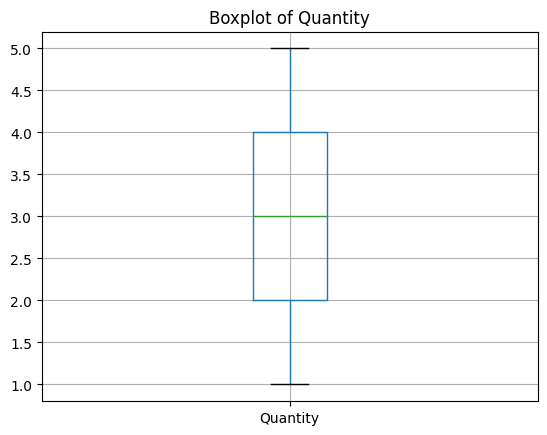

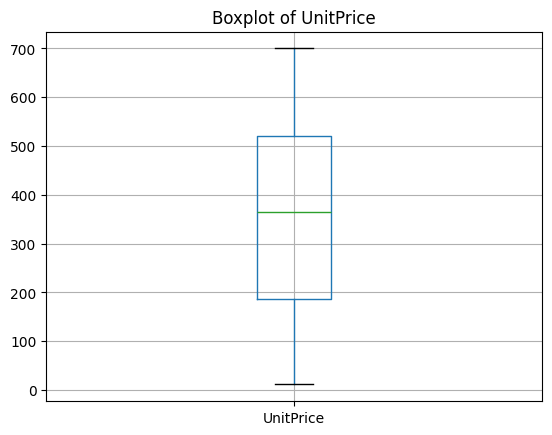

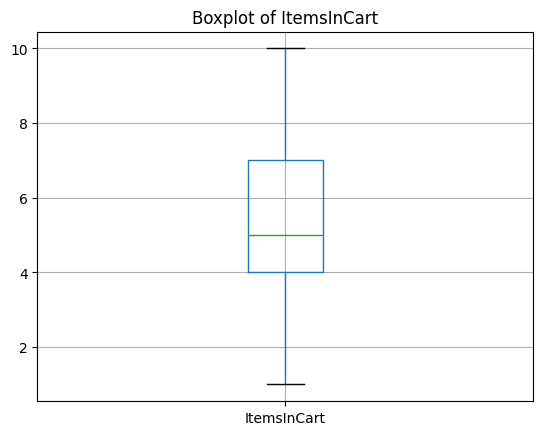

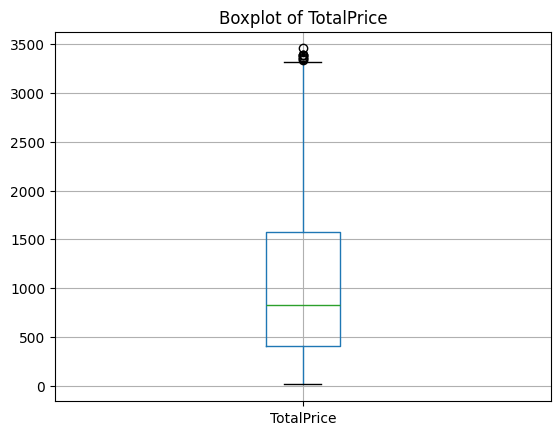

In [15]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(col)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))
    print()

for col in numeric_cols:
    df.boxplot(column=col)
    plt.title(f"Boxplot of {col}")
    plt.show()

DISTRIBUTION

Quantity

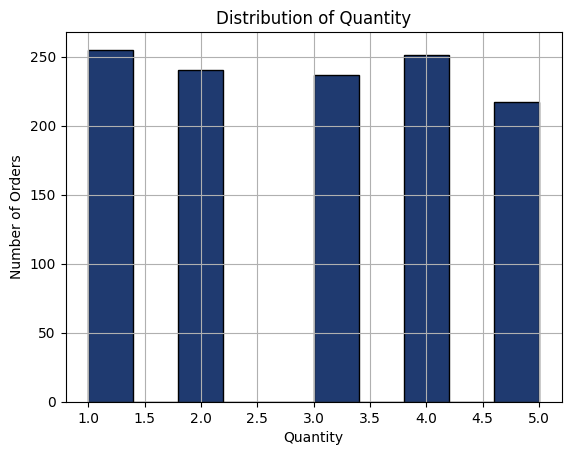

In [16]:
df["Quantity"].hist(bins=10)
plt.title("Distribution of Quantity")
plt.xlabel("Quantity")
plt.ylabel("Number of Orders")
df["Quantity"].hist(bins=10, color="#1F3A70", edgecolor="black")
plt.show()

Unit Price

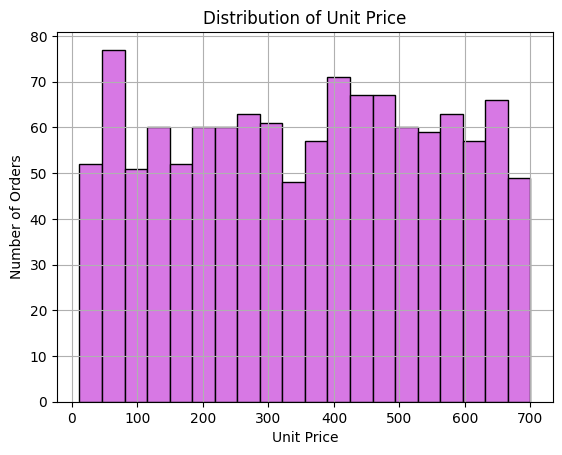

In [17]:
df["UnitPrice"].hist(bins=20)
plt.title("Distribution of Unit Price")
plt.xlabel("Unit Price")
plt.ylabel("Number of Orders")
df["UnitPrice"].hist(bins=20, color="#D778E4", edgecolor="black")
plt.show()

Items in Cart

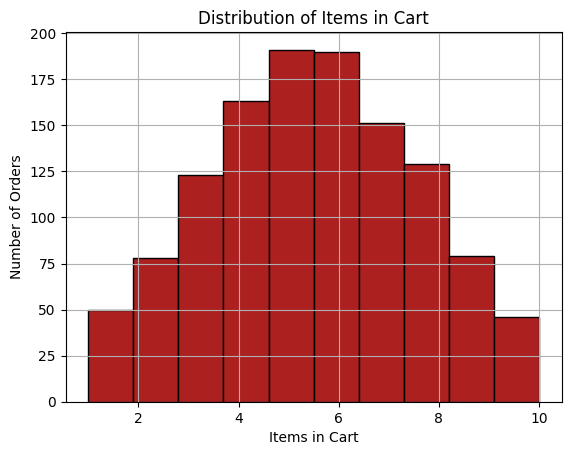

In [18]:
df["ItemsInCart"].hist(bins=10)
plt.title("Distribution of Items in Cart")
plt.xlabel("Items in Cart")
plt.ylabel("Number of Orders")
df["ItemsInCart"].hist(bins=10, color="#AC2020", edgecolor="black")
plt.show()

Total Price

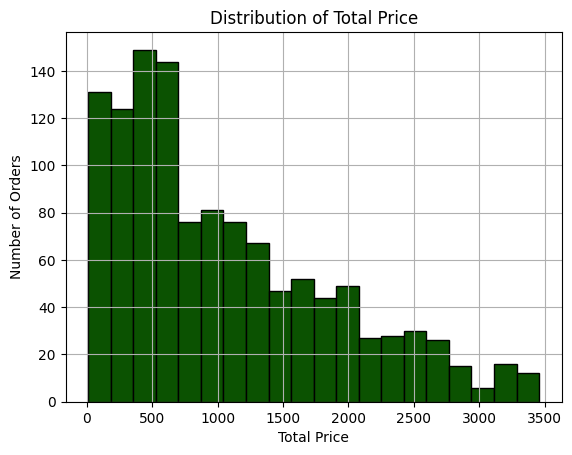

In [19]:
df["TotalPrice"].hist(bins=20)
plt.title("Distribution of Total Price")
plt.xlabel("Total Price")
plt.ylabel("Number of Orders")
df["TotalPrice"].hist(bins=20, color="#0B5201", edgecolor="black")
plt.show()

TRENDS

Monthly Order Trend

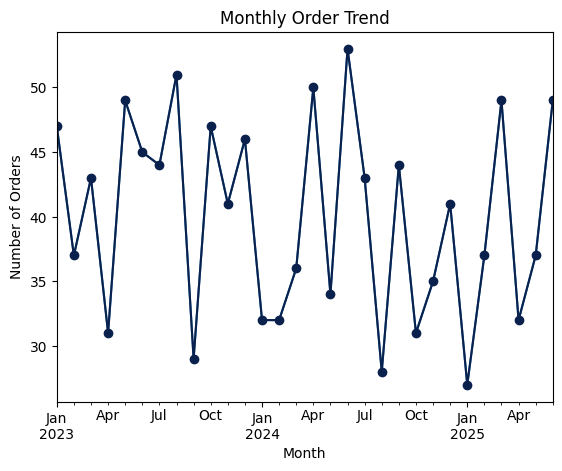

In [20]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_orders = df.groupby("Month").size()

monthly_orders.plot(kind="line")
plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
monthly_orders.plot(kind="line", color="#0B214D", marker="o")
plt.show()

Quantity Sold by Product

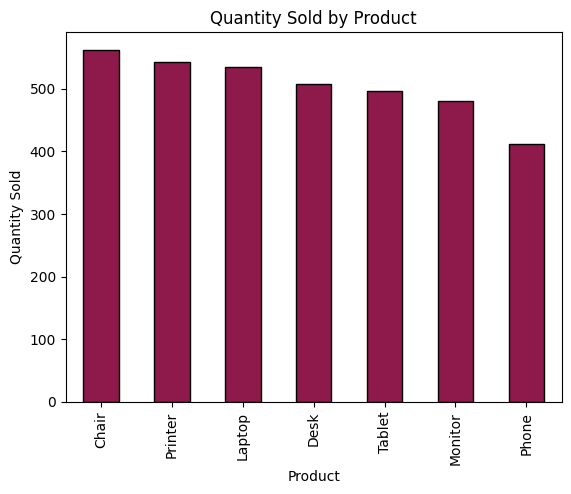

In [21]:
product_sales = df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)

product_sales.plot(kind="bar")
plt.title("Quantity Sold by Product")
plt.xlabel("Product")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
product_sales.plot(kind="bar", color="#8D1A4A", edgecolor="black")
plt.show()

Orders by Payment Method

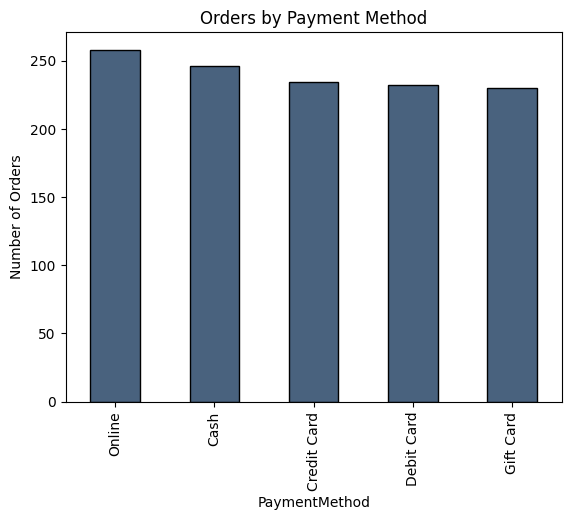

In [22]:
df["PaymentMethod"].value_counts().plot(kind="bar")

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")
df["PaymentMethod"].value_counts().plot(kind="bar", color="#6E505088", edgecolor="black")
plt.show()

Order Status

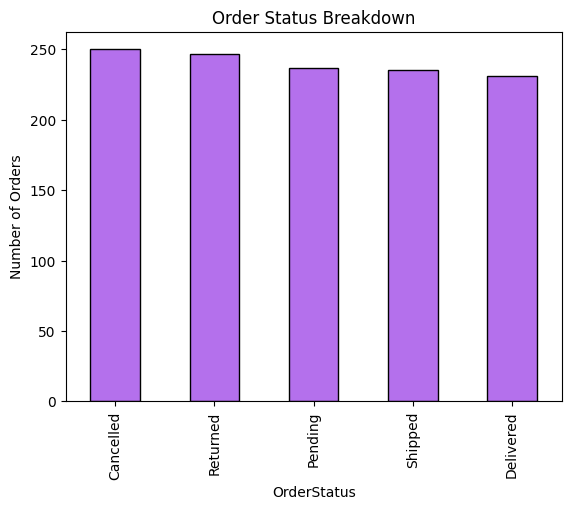

In [23]:
df["OrderStatus"].value_counts().plot(kind="bar")

plt.title("Order Status Breakdown")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
df["OrderStatus"].value_counts().plot(kind="bar", color="#B470EC", edgecolor="black")
plt.show()

Orders by Referral Source

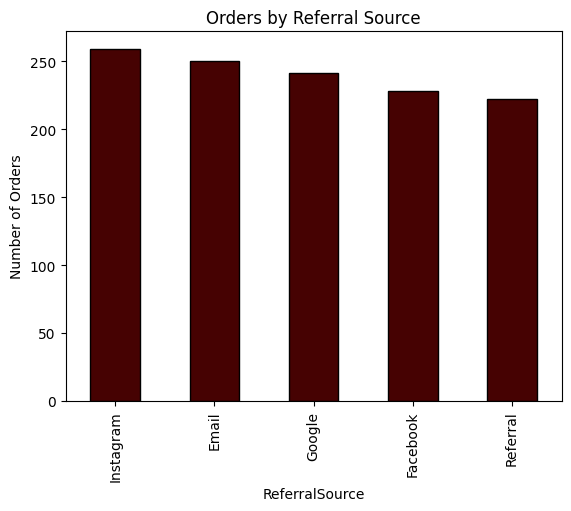

In [24]:
df["ReferralSource"].value_counts().plot(kind="bar")

plt.title("Orders by Referral Source")
plt.xlabel("Referral Source")
plt.ylabel("Number of Orders")
df["ReferralSource"].value_counts().plot(kind="bar", color="#460202", edgecolor="black")
plt.show()

CORRELATION

In [25]:
correlation = df[numeric_cols].corr()
correlation

,Quantity,UnitPrice,ItemsInCart,TotalPrice
Quantity,1.000000,0.014553,0.650061,0.615251
UnitPrice,0.014553,1.000000,0.000602,0.717081
ItemsInCart,0.650061,0.000602,1.000000,0.392540
TotalPrice,0.615251,0.717081,0.392540,1.000000


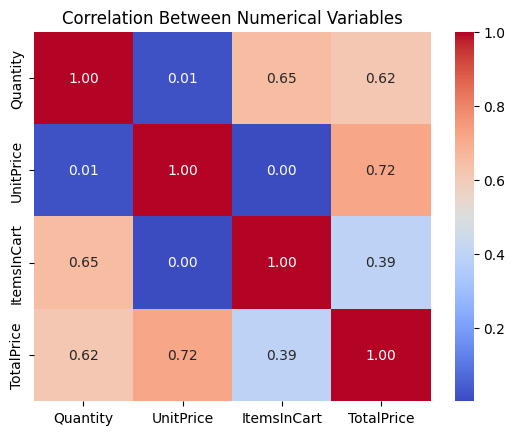

In [26]:
import seaborn as sns
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Variables")
plt.show()

In [27]:
numeric_cols = ["Quantity", "UnitPrice", "ItemsInCart", "TotalPrice"]
df[numeric_cols].agg(["count", "mean", "median"])

,Quantity,UnitPrice,ItemsInCart,TotalPrice
count,1200.000000,1200.00000,1200.000,1200.0000
mean,2.945833,356.41275,5.485,1053.9683
median,3.000000,364.21000,5.000,823.6150


In [28]:
df.to_csv("cleaned_orders.csv", index=False)

project 3

In [29]:
from sqlalchemy import create_engine

In [30]:
engine = create_engine(
    "mssql+pyodbc://DESKTOP-IJ9P2EK\SQLEXPRESS/Order_Dataset"
    "?driver=ODBC+Driver+17+for+SQL+Server"
)

<>:2: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
<>:2: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
C:\Users\Bilal Traders\AppData\Local\Temp\ipykernel_14808\2509662232.py:2: SyntaxWarning: "\S" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\S"? A raw string is also an option.
  "mssql+pyodbc://DESKTOP-IJ9P2EK\SQLEXPRESS/Order_Dataset"


In [46]:
df = pd.read_csv("cleaned_orders.csv")
df.to_sql(
    "Orders",
    con=engine,
    if_exists="replace",
    index=False)

88

Project 4

DATA VISUALIZATION

In [47]:
df = pd.read_csv("cleaned_orders.csv")
df["Date"] = pd.to_datetime(df["Date"])
sns.set_theme(style="whitegrid")

Bar chart:Top 10 products by total sales


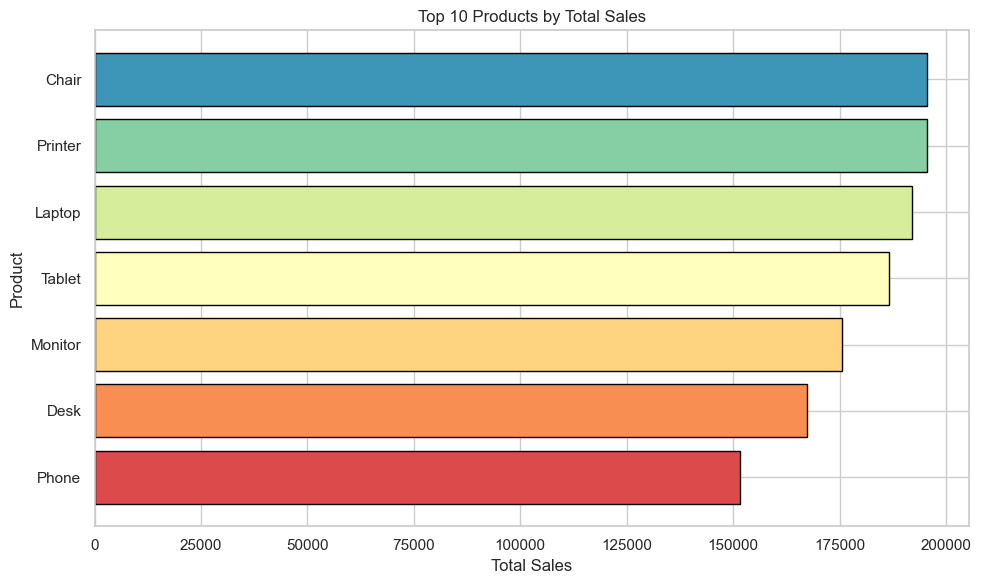

In [48]:
product_revenue = (
    df.groupby("Product")["TotalPrice"]
    .sum()
    .nlargest(10)
    .sort_values()
)

colors = sns.color_palette("Spectral", len(product_revenue))

plt.figure(figsize=(10, 6))
plt.barh(
    product_revenue.index,
    product_revenue.values,
    color=colors,
    edgecolor="black"
)

plt.title("Top 10 Products by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

Area chart: Monthly sales trend

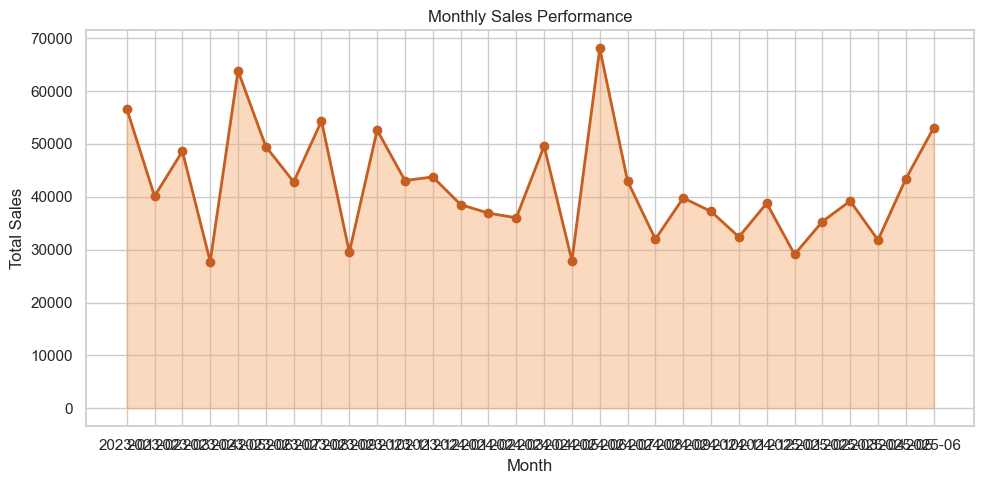

In [49]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["TotalPrice"].sum()
monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(10, 5))

plt.fill_between(
    range(len(monthly_sales)),
    monthly_sales.values,
    color="#F4A261",
    alpha=0.4
)

plt.plot(
    range(len(monthly_sales)),
    monthly_sales.values,
    color="#C65D21",
    marker="o",
    linewidth=2
)

plt.title("Monthly Sales Performance")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(range(len(monthly_sales)), monthly_sales.index, rotation=0)
plt.tight_layout()
plt.show()

Donut chart: Customer payment preferences

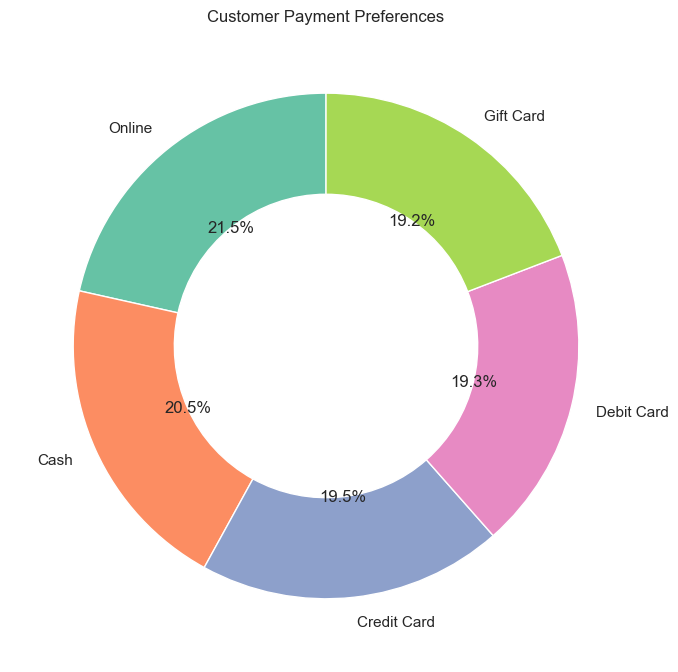

In [50]:
payment_counts = df["PaymentMethod"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=sns.color_palette("Set2", len(payment_counts)),
    wedgeprops={"width": 0.4, "edgecolor": "white"}
)

plt.title("Customer Payment Preferences")
plt.tight_layout()
plt.show()

Horizontal bar chart: Sales by referral source

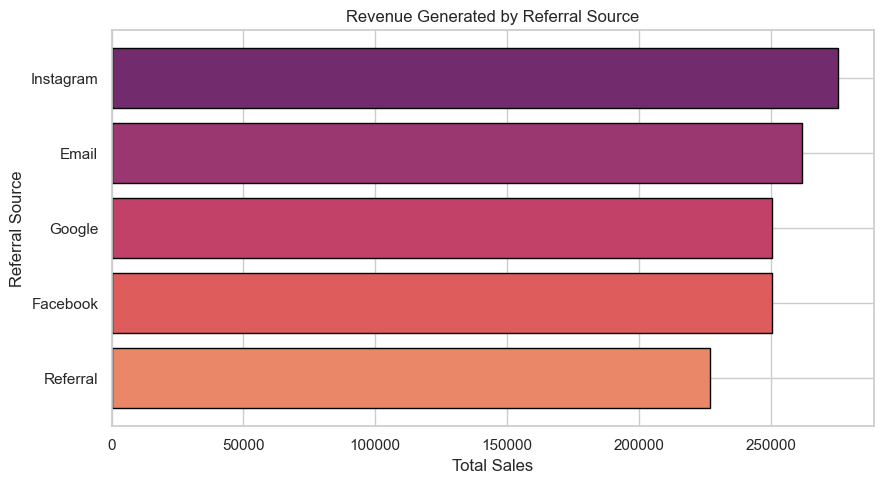

In [51]:
referral_sales = (
    df.groupby("ReferralSource")["TotalPrice"]
    .sum()
    .sort_values()
)

plt.figure(figsize=(9, 5))

plt.barh(
    referral_sales.index,
    referral_sales.values,
    color=sns.color_palette("flare", len(referral_sales)),
    edgecolor="black"
)

plt.title("Revenue Generated by Referral Source")
plt.xlabel("Total Sales")
plt.ylabel("Referral Source")
plt.tight_layout()
plt.show()


Display business insights

In [53]:
print("PROJECT 4: BUSINESS INSIGHTS")
print("-" * 35)

print("Total Orders:", len(df))
print("Unique Customers:", df["CustomerID"].nunique())
print("Total Sales:", round(df["TotalPrice"].sum(), 2))
print("Average Order Value:", round(df["TotalPrice"].mean(), 2))

print(
    "Highest Revenue Product:",
    df.groupby("Product")["TotalPrice"].sum().idxmax()
)

print(
    "Highest Spending Customer:",
    df.groupby("CustomerID")["TotalPrice"].sum().idxmax()
)

print(
    "Best Performing Referral Source:",
    df.groupby("ReferralSource")["TotalPrice"].sum().idxmax()
)


PROJECT 4: BUSINESS INSIGHTS
-----------------------------------
Total Orders: 1200
Unique Customers: 1189
Total Sales: 1264761.96
Average Order Value: 1053.97
Highest Revenue Product: Chair
Highest Spending Customer: C38840
Best Performing Referral Source: Instagram
